# IC Spike times and LFP

## Importing the Libraries and the Paths in case of Notebook Re-Run

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import seaborn as sns
%matplotlib widget

import spikeinterface as si
import spikeinterface.extractors as se
import spikeinterface.preprocessing as spre
import spikeinterface.widgets as sw

In [2]:
# Data paths
# SP1
sp1_path = Path("/Volumes/AFedor_T7/TTK-NeuroData/sp_1_20171017/spike_sorting_Thresh_9_9/Data/")
# SP6
sp6_path = Path("/Volumes/AFedor_T7/TTK-NeuroData/sp_6_20180628/spike_sorting_Thresh_9_9/Data/")
# SP7
sp7_path = Path("/Volumes/AFedor_T7/TTK-NeuroData/sp_7_20190305/spike_sorting_Thresh_9_9/Data/")
# SP9
sp9_path = Path("/Volumes/AFedor_T7/TTK-NeuroData/sp_9_20220215/spike_sorting_Thresh_9_9/Data/")

In [4]:
# Define the folders for each dataset - IC spikes' .ev2 files are in the root of each folder, and the raw recodings in .dat files are in the Data subfolder
sp1_folder = Path("/Volumes/AFedor_T7/TTK-NeuroData/sp_1_20171017/")
sp6_folder = Path("/Volumes/AFedor_T7/TTK-NeuroData/sp_6_20180628/")
sp7_folder = Path("/Volumes/AFedor_T7/TTK-NeuroData/sp_7_20190305/")
sp9_folder = Path("/Volumes/AFedor_T7/TTK-NeuroData/sp_9_20220215/")

In [5]:
# Filtered LFP paths
filtered_lfp_paths = {
    "sp1_01": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp1_01/optimal",
    "sp1_02": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp1_02/optimal",
    "sp1_03": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp1_03/optimal",
    "sp1_04": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp1_04/optimal",
    "sp6_01": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp6_01/optimal",
    "sp6_02": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp6_02/optimal",
    "sp6_03": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp6_03/optimal",
    "sp6_04": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp6_04/optimal",
    "sp7_01": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp7_01/optimal",
    "sp7_02": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp7_02/optimal",
    "sp9_01": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp9_01/optimal",
    "sp9_02": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp9_02/optimal",
    "sp9_03": "/Volumes/AFedor_T7/TTK-NeuroData/LFP codes/cached/own_data/sp9_03/optimal",
}

## Load the Filtered Recordings from the Cached Folder

In [6]:
# Load the recordings from the cache to save time in case the notebook is re-run
recordings = dict()
for path in filtered_lfp_paths.keys():
    recording_name = path
    print(f"Loading recording: {recording_name}")
    recordings[recording_name] = si.load(filtered_lfp_paths[path])

Loading recording: sp1_01
Loading recording: sp1_02
Loading recording: sp1_03
Loading recording: sp1_04
Loading recording: sp6_01
Loading recording: sp6_02
Loading recording: sp6_03
Loading recording: sp6_04
Loading recording: sp7_01
Loading recording: sp7_02
Loading recording: sp9_01
Loading recording: sp9_02
Loading recording: sp9_03


In [7]:
n_ch = 32
for rec in recordings.keys():
    recordings[rec].set_property("gain_to_uV", [1.0] * n_ch)
    recordings[rec].set_property("offset_to_uV", [0.0] * n_ch)

## Load IC Spike times from .ev2

In [8]:
# Loading all IC spike times from the .ev2 event files for further analysis
IC_spike_times = {}
for folder in [sp1_folder, sp6_folder, sp7_folder, sp9_folder]:
    sp_id = folder.name.split('_')[0] + folder.name.split('_')[1]  # Extract the SP index from the folder name e.g. sp1, sp6, sp7, sp9
    for recording_id in ['01', '02', '03', '04']:
        recording = f"{sp_id}_{recording_id}"
        print(f"Loading IC spike times for {recording}")
        ev2_file = Path(f"{folder}/{recording_id}.ev2")
        if ev2_file.exists():
            ic_spike_times = np.loadtxt(ev2_file, usecols=5)
            IC_spike_times[recording] = ic_spike_times
            print(f"Loaded IC spike times for {recording}: {ic_spike_times.shape[0]} spikes")
        else:
            print(f"File not found for {recording}")

Loading IC spike times for sp1_01
Loaded IC spike times for sp1_01: 453 spikes
Loading IC spike times for sp1_02
Loaded IC spike times for sp1_02: 755 spikes
Loading IC spike times for sp1_03
Loaded IC spike times for sp1_03: 757 spikes
Loading IC spike times for sp1_04
Loaded IC spike times for sp1_04: 806 spikes
Loading IC spike times for sp6_01
Loaded IC spike times for sp6_01: 678 spikes
Loading IC spike times for sp6_02
Loaded IC spike times for sp6_02: 793 spikes
Loading IC spike times for sp6_03
Loaded IC spike times for sp6_03: 235 spikes
Loading IC spike times for sp6_04
Loaded IC spike times for sp6_04: 312 spikes
Loading IC spike times for sp7_01
Loaded IC spike times for sp7_01: 600 spikes
Loading IC spike times for sp7_02
Loaded IC spike times for sp7_02: 109 spikes
Loading IC spike times for sp7_03
File not found for sp7_03
Loading IC spike times for sp7_04
File not found for sp7_04
Loading IC spike times for sp9_01
Loaded IC spike times for sp9_01: 822 spikes
Loading IC 

In [9]:
# Delete recordings that have no .ev2 file (not all experiments have 4 different recordings)
for recording, spike_times in IC_spike_times.items():
    if spike_times.size == 0:
        IC_spike_times.pop(recording)
print(IC_spike_times.keys())  # Print the keys of the dictionary to see which recordings have IC spike times loaded

dict_keys(['sp1_01', 'sp1_02', 'sp1_03', 'sp1_04', 'sp6_01', 'sp6_02', 'sp6_03', 'sp6_04', 'sp7_01', 'sp7_02', 'sp9_01', 'sp9_02', 'sp9_03'])


## Visualize IC spikes on the LFP

Use the 20kHz filtered LFP recordings and the IC spike times for visualizing the patched cell's activity in relation to the LFP. 

The IC spike times can be used to align the LFP traces to the spikes, allowing for analysis of the relationship between the two signals.

### Convert IC spike times to seconds

In [10]:
# The IC spike times are in data points. 20kHz sampling rate and 180s recording duration.
# Convert the IC spike times into seconds for indexing
IC_spike_times_sec = {rec: times / 20000.0 for rec, times in IC_spike_times.items()}
print(IC_spike_times_sec.keys())  # Print the keys of the dictionary to see which recordings have IC spike times in seconds loaded
print({rec: times[:5] for rec, times in IC_spike_times_sec.items()})  # Print the first 5 spike times for each recording

dict_keys(['sp1_01', 'sp1_02', 'sp1_03', 'sp1_04', 'sp6_01', 'sp6_02', 'sp6_03', 'sp6_04', 'sp7_01', 'sp7_02', 'sp9_01', 'sp9_02', 'sp9_03'])
{'sp1_01': array([0.00495, 0.08705, 0.1719 , 0.2516 , 0.3319 ]), 'sp1_02': array([0.20505, 0.37735, 0.56515, 0.7007 , 0.82895]), 'sp1_03': array([0.1696 , 0.32995, 0.5688 , 0.83355, 1.0602 ]), 'sp1_04': array([0.07125, 0.30865, 0.50435, 0.6997 , 0.8883 ]), 'sp6_01': array([0.0983 , 0.27295, 0.4623 , 0.662  , 0.8571 ]), 'sp6_02': array([0.03165, 0.2671 , 0.4775 , 0.72135, 0.90745]), 'sp6_03': array([0.0926 , 2.47935, 3.5332 , 4.49095, 5.00715]), 'sp6_04': array([1.3753 , 1.972  , 2.44365, 2.80195, 3.56585]), 'sp7_01': array([2.0834 , 2.09545, 2.23945, 2.4005 , 2.5596 ]), 'sp7_02': array([4.6086 , 4.61815, 4.9228 , 5.11865, 5.3949 ]), 'sp9_01': array([0.2328 , 0.44265, 0.6097 , 1.00565, 1.38395]), 'sp9_02': array([0.0111 , 0.21875, 0.6108 , 0.8224 , 0.9628 ]), 'sp9_03': array([0.0328 , 0.2035 , 0.3883 , 0.59255, 1.01115])}


### Plot LFP traces and well marked IC spikes using static MatPlotLib plots

Text(0.5, 0, 'Time (s)')

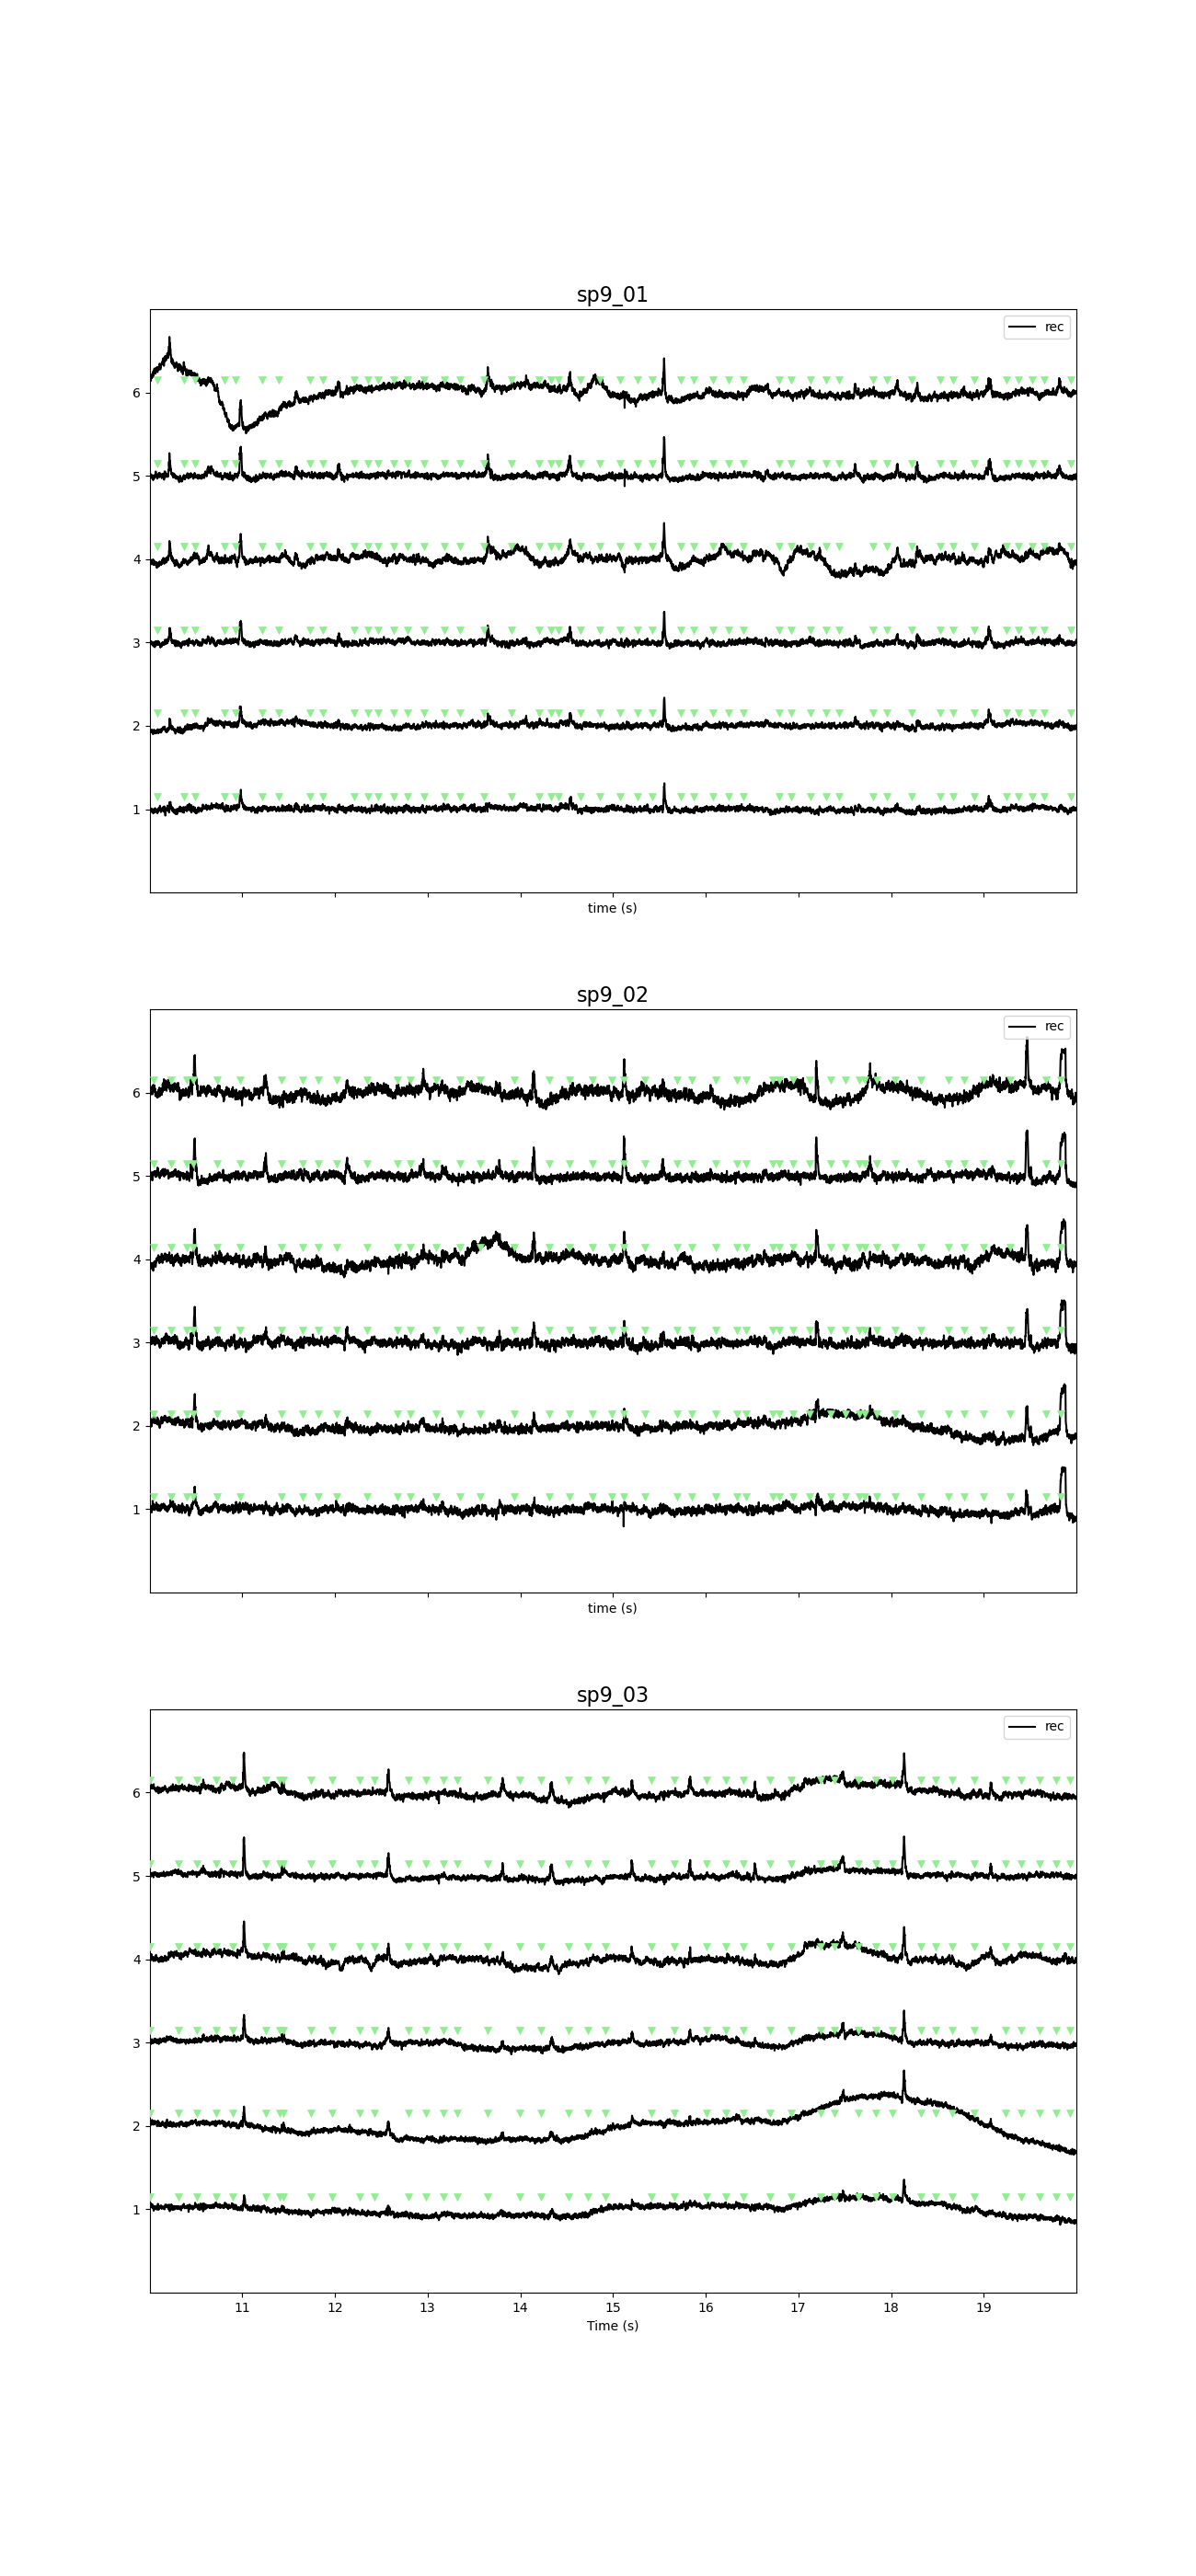

In [11]:
# Plot the 20kHz filtered LFP traces and mark the IC spike times on the plot for the recordings of SP9
channels_to_plot = [1, 2, 3, 4, 5, 6]  # Specify the channels you want to plot
time_window = [10, 20]  # Specify the time window in seconds for plotting

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(13, 28), sharex=True)
sw.plot_traces(recordings["sp9_01"], ax=axs[0], channel_ids=channels_to_plot, show_channel_ids=True, time_range=time_window)
sw.plot_traces(recordings["sp9_02"], ax=axs[1], channel_ids=channels_to_plot, show_channel_ids=True, time_range=time_window)
sw.plot_traces(recordings["sp9_03"], ax=axs[2], channel_ids=channels_to_plot, show_channel_ids=True, time_range=time_window)

# Place a small v-shaped marker slightly above the baseline of every rendered trace.
for ax, recording_id in zip(axs, ["sp9_01", "sp9_02", "sp9_03"]):
    spike_times_sec = IC_spike_times_sec[recording_id]
    spike_times_in_window = spike_times_sec[
        (spike_times_sec >= time_window[0]) & (spike_times_sec <= time_window[1])
    ]

    trace_lines = ax.get_lines()[-len(channels_to_plot):]
    channel_baselines = [np.median(line.get_ydata()) for line in trace_lines]
    baseline_spacing = np.median(np.abs(np.diff(channel_baselines)))
    marker_offset = 0.15 * baseline_spacing

    for channel_y in channel_baselines:
        ax.plot(
            spike_times_in_window,
            np.full(spike_times_in_window.shape, channel_y + marker_offset),
            linestyle="None",
            marker="v",
            markersize=6,
            markeredgewidth=0.5,
            color="lightgreen",
            zorder=10,
        )
    ax.set_title(recording_id, fontsize=16)
axs[-1].set_xlabel("Time (s)")

### Plot LFP traces and vline marked IC spikes using interactive *ipywidgets* plots

In [12]:
# Plot the 20kHz filtered LFP traces and mark the IC spike times on the plot for the recordings of SP9
# Let's try the ipywidgets backend
_ = sw.plot_traces(recordings["sp9_01"], backend = "ipywidgets", events = IC_spike_times_sec["sp9_01"], events_color = "red")
_ = sw.plot_traces(recordings["sp9_02"], backend = "ipywidgets", events = IC_spike_times_sec["sp9_02"], events_color = "red")
_ = sw.plot_traces(recordings["sp9_03"], backend = "ipywidgets", events = IC_spike_times_sec["sp9_03"], events_color = "red")


AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

## Load SPW times from .ev2 files

In [13]:
# We use the pre-loaded sp..._folder variables to load the SW times for SP1, SP6, SP7, and SP9.
SPW_peaks = {}
for folder in [sp1_folder, sp6_folder, sp7_folder, sp9_folder]:
    sp_id = folder.name.split('_')[0] + folder.name.split('_')[1]  # Extract the SP index from the folder name e.g. sp1, sp6, sp7, sp9
    for recording_id in ['01', '02', '03', '04']:
        spw_file = Path(f"{folder}/spike_sorting_Thresh_9_9/Data/{recording_id}/{recording_id}_spa_peaks.ev2")
        print(f"Loading SW times for {sp_id}_{recording_id}")
        if spw_file.exists():
            spw_peaks = np.loadtxt(spw_file, usecols=5, skiprows=1)  # Load the SW times as integers (data points)
            SPW_peaks[f"{sp_id}_{recording_id}"] = spw_peaks
            print(f"Loaded SW times for {sp_id}_{recording_id}: {spw_peaks.shape[0]} events")
        else:
            print(f"File not found for {sp_id}_{recording_id}")

Loading SW times for sp1_01
Loaded SW times for sp1_01: 40 events
Loading SW times for sp1_02
Loaded SW times for sp1_02: 39 events
Loading SW times for sp1_03
Loaded SW times for sp1_03: 31 events
Loading SW times for sp1_04
File not found for sp1_04
Loading SW times for sp6_01
Loaded SW times for sp6_01: 101 events
Loading SW times for sp6_02
Loaded SW times for sp6_02: 93 events
Loading SW times for sp6_03
Loaded SW times for sp6_03: 91 events
Loading SW times for sp6_04
Loaded SW times for sp6_04: 95 events
Loading SW times for sp7_01
Loaded SW times for sp7_01: 126 events
Loading SW times for sp7_02
Loaded SW times for sp7_02: 82 events
Loading SW times for sp7_03
File not found for sp7_03
Loading SW times for sp7_04
File not found for sp7_04
Loading SW times for sp9_01
Loaded SW times for sp9_01: 197 events
Loading SW times for sp9_02
Loaded SW times for sp9_02: 207 events
Loading SW times for sp9_03
Loaded SW times for sp9_03: 197 events
Loading SW times for sp9_04
File not foun

In [14]:
# Delete recordings that have no .ev2 file (not all experiments have 4 different recordings)
for recording, spw_peaks in SPW_peaks.items():
    if spw_peaks.size == 0:
        SPW_peaks.pop(recording)
print(SPW_peaks.keys())  # Print the keys of the dictionary to see which recordings have SW times loaded

dict_keys(['sp1_01', 'sp1_02', 'sp1_03', 'sp6_01', 'sp6_02', 'sp6_03', 'sp6_04', 'sp7_01', 'sp7_02', 'sp9_01', 'sp9_02', 'sp9_03'])


## Visualize SPW events on the LFP

### Convert SPW times to seconds

In [15]:
SPW_peaks_sec = {rec: peaks / 20000.0 for rec, peaks in SPW_peaks.items()}
print(SPW_peaks_sec.keys())  # Print the keys of the dictionary to see which recordings have SW times in seconds loaded
print({rec: peaks[:5] for rec, peaks in SPW_peaks_sec.items()})  # Print the first 5 SW times for each recording

dict_keys(['sp1_01', 'sp1_02', 'sp1_03', 'sp6_01', 'sp6_02', 'sp6_03', 'sp6_04', 'sp7_01', 'sp7_02', 'sp9_01', 'sp9_02', 'sp9_03'])
{'sp1_01': array([ 5.3295,  7.5205,  9.526 , 10.4   , 23.3705]), 'sp1_02': array([ 8.6905, 13.6795, 14.573 , 22.735 , 24.6145]), 'sp1_03': array([ 6.0955,  9.1375, 11.9165, 13.796 , 27.8325]), 'sp6_01': array([4.1565, 4.697 , 5.829 , 7.1935, 7.734 ]), 'sp6_02': array([2.2705, 4.7735, 6.1215, 8.271 , 9.95  ]), 'sp6_03': array([ 4.25  ,  5.062 ,  8.0055, 10.2095, 10.434 ]), 'sp6_04': array([ 3.836 ,  6.6105,  9.938 , 11.076 , 11.7255]), 'sp7_01': array([2.51  , 3.9715, 5.201 , 6.1125, 6.6105]), 'sp7_02': array([3.9375, 5.745 , 6.227 , 8.2375, 9.957 ]), 'sp9_01': array([3.    , 3.121 , 4.3415, 5.3905, 6.4335]), 'sp9_02': array([0.3595, 3.4385, 4.2565, 4.925 , 5.9785]), 'sp9_03': array([2.741 , 3.459 , 4.3835, 5.6235, 6.0505])}


### Create time epochs around SPW peaks

In [17]:
# Create a +- 100 ms window around each SPW peak time for further analysis
fs = 20000  # Sampling frequency in Hz
epoch_size = 0.2 * fs  # 200 ms window in data points
SPW_windows = {}

for recording, peaks in SPW_peaks.items():
    windows = []
    print(f"Creating windows for {recording}")
    for peak in peaks:
        start = int(max(0, peak - epoch_size / 2))
        end = int(min(fs*180, peak + epoch_size / 2))
        windows.append((start, end))
    SPW_windows[recording] = np.array(windows)
    print(f"Created {len(windows)} windows for {recording}")

print(SPW_windows.keys())  # Print the keys of the dictionary to see which recordings have SW windows created
print({rec: windows[:5] for rec, windows in SPW_windows.items()})  # Print the first 5 SW windows for each recording

Creating windows for sp1_01
Created 40 windows for sp1_01
Creating windows for sp1_02
Created 39 windows for sp1_02
Creating windows for sp1_03
Created 31 windows for sp1_03
Creating windows for sp6_01
Created 101 windows for sp6_01
Creating windows for sp6_02
Created 93 windows for sp6_02
Creating windows for sp6_03
Created 91 windows for sp6_03
Creating windows for sp6_04
Created 95 windows for sp6_04
Creating windows for sp7_01
Created 126 windows for sp7_01
Creating windows for sp7_02
Created 82 windows for sp7_02
Creating windows for sp9_01
Created 197 windows for sp9_01
Creating windows for sp9_02
Created 207 windows for sp9_02
Creating windows for sp9_03
Created 197 windows for sp9_03
dict_keys(['sp1_01', 'sp1_02', 'sp1_03', 'sp6_01', 'sp6_02', 'sp6_03', 'sp6_04', 'sp7_01', 'sp7_02', 'sp9_01', 'sp9_02', 'sp9_03'])
{'sp1_01': array([[104590, 108590],
       [148410, 152410],
       [188520, 192520],
       [206000, 210000],
       [465410, 469410]]), 'sp1_02': array([[171810, 175

In [18]:
SPW_windows_sec = {rec: windows / fs for rec, windows in SPW_windows.items()}
print(SPW_windows_sec.keys())  # Print the keys of the dictionary to see which recordings have SW windows in seconds created
print({rec: windows[:5] for rec, windows in SPW_windows_sec.items()})  # Print the first 5 SW windows in seconds for each recording

dict_keys(['sp1_01', 'sp1_02', 'sp1_03', 'sp6_01', 'sp6_02', 'sp6_03', 'sp6_04', 'sp7_01', 'sp7_02', 'sp9_01', 'sp9_02', 'sp9_03'])
{'sp1_01': array([[ 5.2295,  5.4295],
       [ 7.4205,  7.6205],
       [ 9.426 ,  9.626 ],
       [10.3   , 10.5   ],
       [23.2705, 23.4705]]), 'sp1_02': array([[ 8.5905,  8.7905],
       [13.5795, 13.7795],
       [14.473 , 14.673 ],
       [22.635 , 22.835 ],
       [24.5145, 24.7145]]), 'sp1_03': array([[ 5.9955,  6.1955],
       [ 9.0375,  9.2375],
       [11.8165, 12.0165],
       [13.696 , 13.896 ],
       [27.7325, 27.9325]]), 'sp6_01': array([[4.0565, 4.2565],
       [4.597 , 4.797 ],
       [5.729 , 5.929 ],
       [7.0935, 7.2935],
       [7.634 , 7.834 ]]), 'sp6_02': array([[ 2.1705,  2.3705],
       [ 4.6735,  4.8735],
       [ 6.0215,  6.2215],
       [ 8.171 ,  8.371 ],
       [ 9.85  , 10.05  ]]), 'sp6_03': array([[ 4.15  ,  4.35  ],
       [ 4.962 ,  5.162 ],
       [ 7.9055,  8.1055],
       [10.1095, 10.3095],
       [10.334 , 10.534 

### Plot LFP traces and SPW epochs as events using the static MatPlotLib plots

In [36]:
# To plot events with a duration, the sw.plot_traces function requires an event time and a duration.
# Thus we need to create a new array with the start times and durations of the SW windows for each recording.
event_dtype = np.dtype([('time', 'float64'), ('duration', 'float64')])
SPW_events_for_plotting = {}

for recording, windows in SPW_windows_sec.items():
    start_times = windows[:, 0]
    durations = np.full(start_times.shape, 0.2, dtype=event_dtype['duration']) # seconds, since we created a +- 100 ms window around each SPW peak time
    events = np.empty(start_times.shape[0], dtype=event_dtype)
    events['time'] = start_times
    events['duration'] = durations
    SPW_events_for_plotting[recording] = events

print(SPW_events_for_plotting.keys())  # Print the keys of the dictionary to see which recordings have SW events for plotting
print(SPW_events_for_plotting["sp9_01"].dtype)
print({rec: events[:5] for rec, events in SPW_events_for_plotting.items()})  # Print the first 5 SW events for plotting for each recording

dict_keys(['sp1_01', 'sp1_02', 'sp1_03', 'sp6_01', 'sp6_02', 'sp6_03', 'sp6_04', 'sp7_01', 'sp7_02', 'sp9_01', 'sp9_02', 'sp9_03'])
[('time', '<f8'), ('duration', '<f8')]
{'sp1_01': array([( 5.2295, 0.2), ( 7.4205, 0.2), ( 9.426 , 0.2), (10.3   , 0.2),
       (23.2705, 0.2)], dtype=[('time', '<f8'), ('duration', '<f8')]), 'sp1_02': array([( 8.5905, 0.2), (13.5795, 0.2), (14.473 , 0.2), (22.635 , 0.2),
       (24.5145, 0.2)], dtype=[('time', '<f8'), ('duration', '<f8')]), 'sp1_03': array([( 5.9955, 0.2), ( 9.0375, 0.2), (11.8165, 0.2), (13.696 , 0.2),
       (27.7325, 0.2)], dtype=[('time', '<f8'), ('duration', '<f8')]), 'sp6_01': array([(4.0565, 0.2), (4.597 , 0.2), (5.729 , 0.2), (7.0935, 0.2),
       (7.634 , 0.2)], dtype=[('time', '<f8'), ('duration', '<f8')]), 'sp6_02': array([(2.1705, 0.2), (4.6735, 0.2), (6.0215, 0.2), (8.171 , 0.2),
       (9.85  , 0.2)], dtype=[('time', '<f8'), ('duration', '<f8')]), 'sp6_03': array([( 4.15  , 0.2), ( 4.962 , 0.2), ( 7.9055, 0.2), (10.1095, 0.2

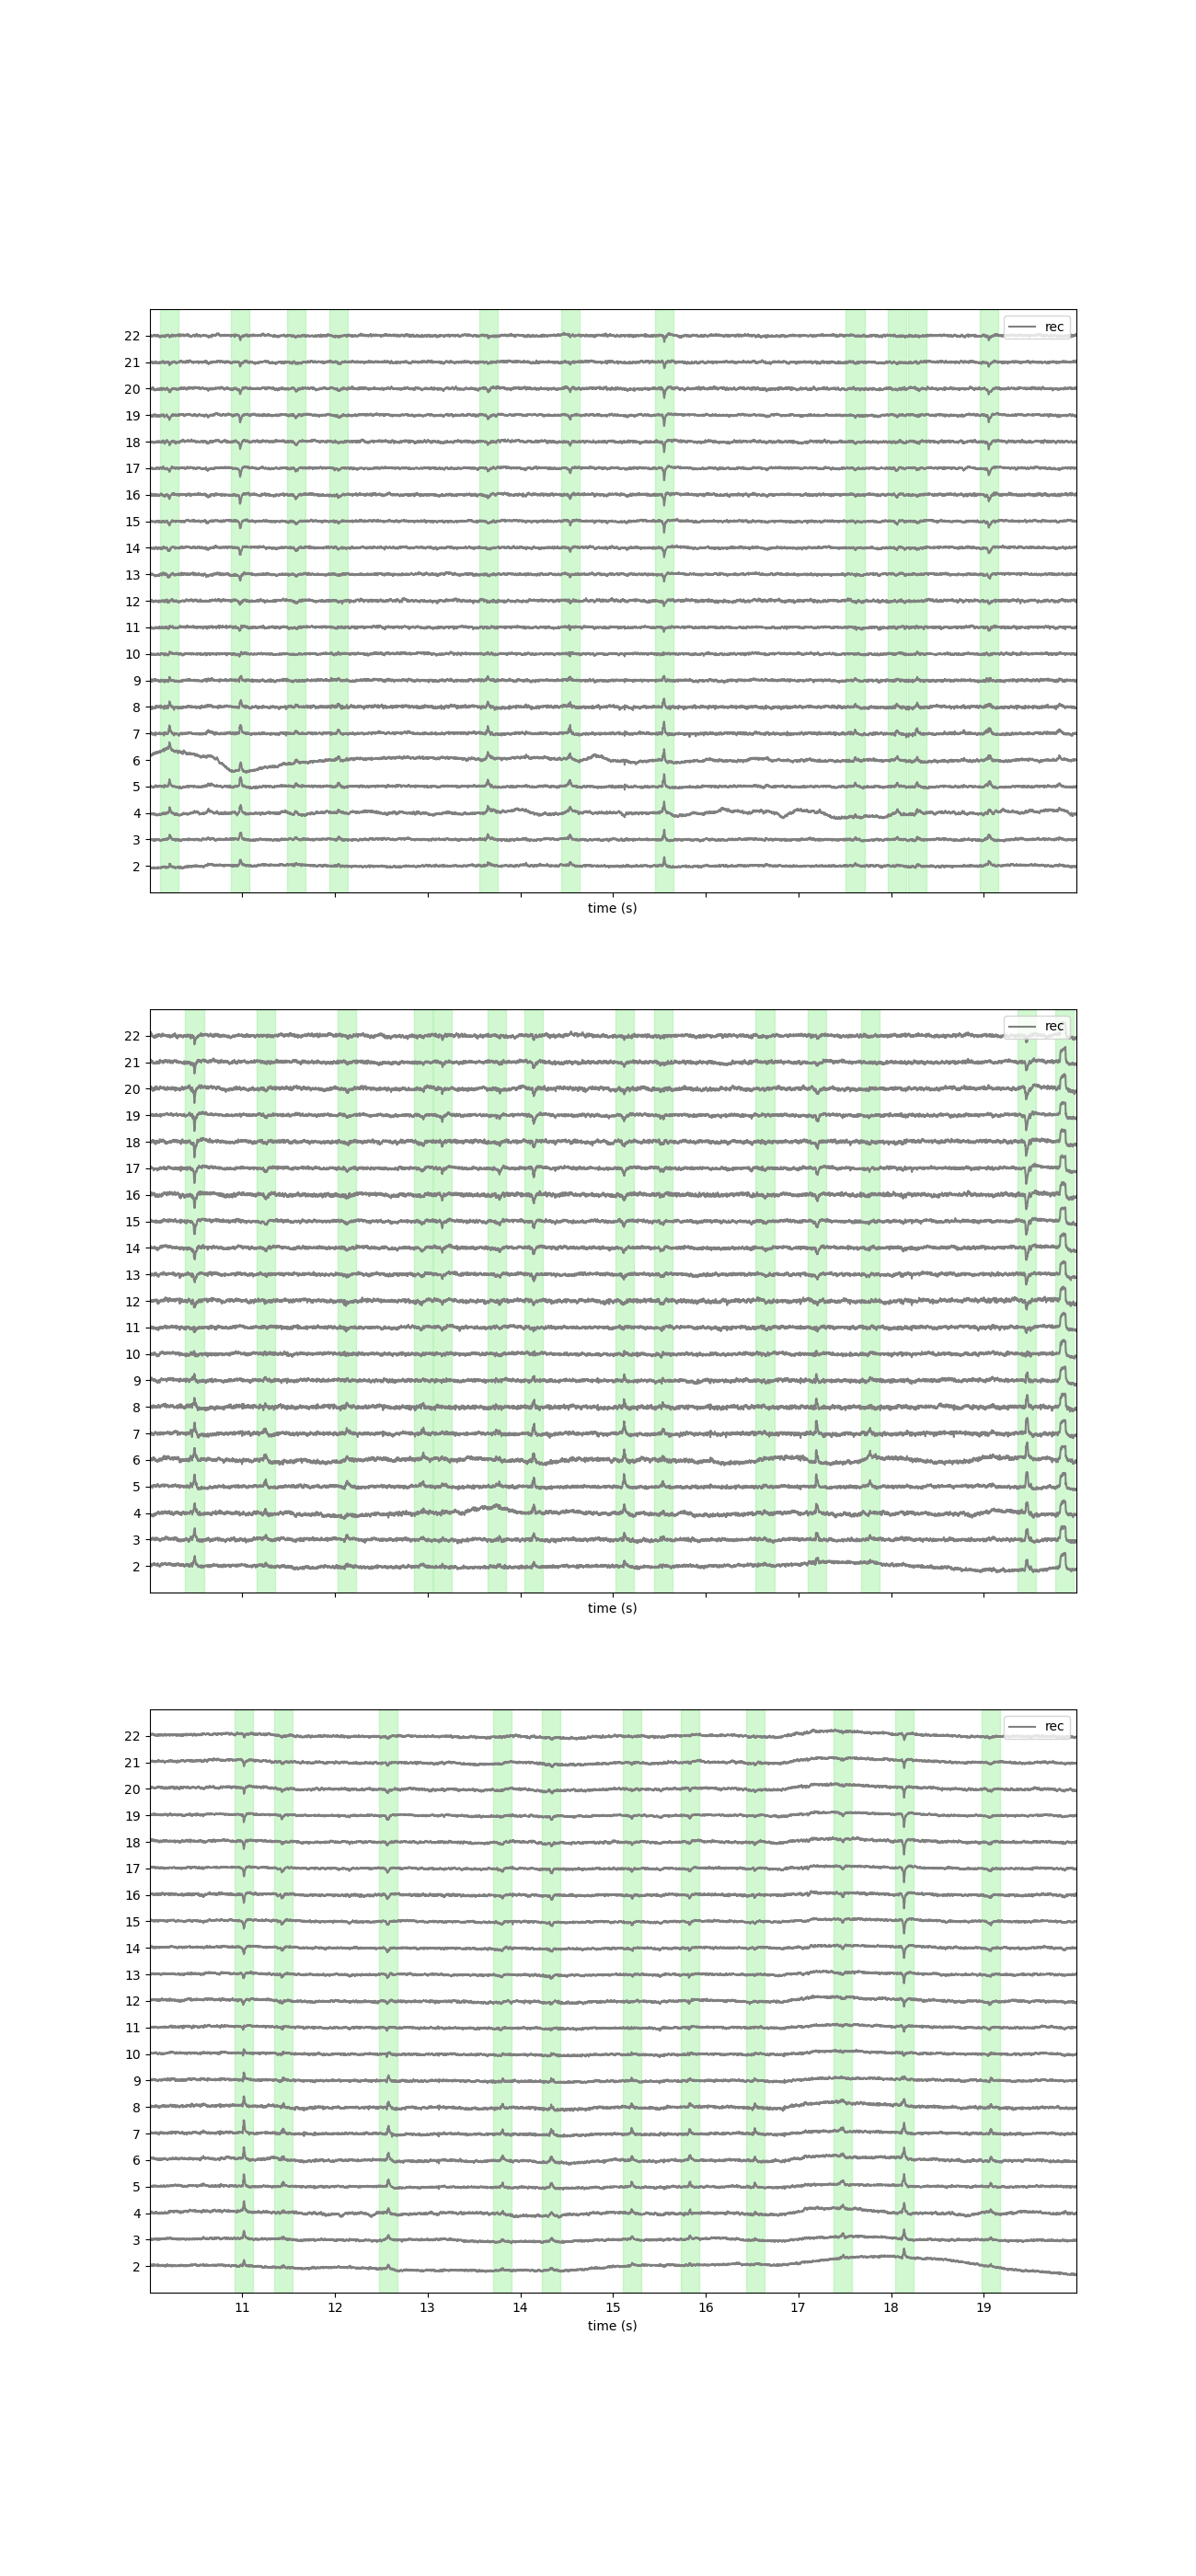

In [37]:
# Here, I will only plot the SW times for SP9 recordings.
channels_to_plot = np.arange(2, 23)  # Specify the channels you want to plot
time_window = [10, 20]  # Specify the time window in seconds for plotting

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(13, 28), sharex=True)
sw.plot_traces(recordings["sp9_01"], ax=axs[0], channel_ids=channels_to_plot, show_channel_ids=True, time_range=time_window, color='grey', events=SPW_events_for_plotting["sp9_01"], events_color="lightgreen", events_alpha=0.4)
sw.plot_traces(recordings["sp9_02"], ax=axs[1], channel_ids=channels_to_plot, show_channel_ids=True, time_range=time_window, color='grey', events=SPW_events_for_plotting["sp9_02"], events_color="lightgreen", events_alpha=0.4)
sw.plot_traces(recordings["sp9_03"], ax=axs[2], channel_ids=channels_to_plot, show_channel_ids=True, time_range=time_window, color='grey', events=SPW_events_for_plotting["sp9_03"], events_color="lightgreen", events_alpha=0.4)

### Plot the LFP traces and SPW epochs as events using the interactive *ipywidgets* plots

In [38]:
# Let's try the ipywidgets backend
_ = sw.plot_traces(recordings["sp9_01"], backend = "ipywidgets", events = SPW_events_for_plotting["sp9_01"], events_color = "lightgreen", events_alpha = 0.4)
_ = sw.plot_traces(recordings["sp9_02"], backend = "ipywidgets", events = SPW_events_for_plotting["sp9_02"], events_color = "lightgreen", events_alpha = 0.4)
_ = sw.plot_traces(recordings["sp9_03"], backend = "ipywidgets", events = SPW_events_for_plotting["sp9_03"], events_color = "lightgreen", events_alpha = 0.4)


AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…